# Exploratory Data Analysis: Employee Performance Analysis, INX Future Inc.

**Business questions this notebook helps answer**
1. How does performance differ between departments? (Required insight 1)
2. Which factors are related to employee performance? (Required insight 2, first look)
3. Who are the lower-performing employees, and what do they have in common? (CEO's request for clear indicators)

Statistical tests are used alongside charts so conclusions do not rest on visual impressions alone.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option('display.max_columns', 60, 'display.width', 200)
sns.set_theme(style='whitegrid', palette='deep')
ROOT = Path('../..').resolve()
df = pd.read_csv(ROOT/'data'/'processed'/'employee_clean.csv')
mr = pd.read_csv(ROOT/'data'/'processed'/'employee_model_ready.csv')
print(df.shape)

(1200, 32)


## 1. The target: performance rating

In [2]:
dist = df['PerformanceRating'].value_counts().sort_index()
pd.DataFrame({'employees':dist, 'share_%':(100*dist/len(df)).round(1),
              'meaning':['Good','Excellent','Outstanding']}, index=dist.index)

,employees,share_%,meaning
PerformanceRating,,,
2,194,16.2,Good
3,874,72.8,Excellent
4,132,11.0,Outstanding


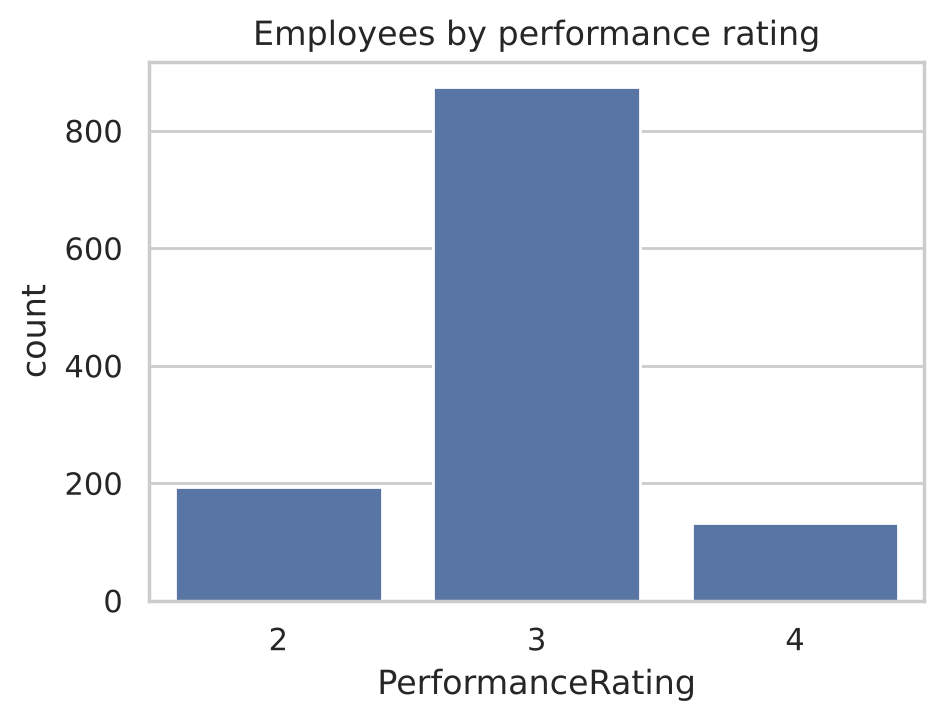

In [3]:
fig, ax = plt.subplots(figsize=(5,3.5))
sns.countplot(data=df, x='PerformanceRating', ax=ax)
ax.set_title('Employees by performance rating'); plt.show()

Most employees (about 73%) are rated 3. Ratings of 2 (about 16%) and 4 (about 11%) are the minority classes. This **class imbalance** matters later: a model that always predicts "3" would already be about 73% accurate, so we judge models by balanced measures (macro F1) and not accuracy alone.

## 2. Department-wise performance (required insight 1)

In [4]:
dept = df.groupby('EmpDepartment').agg(
    employees=('PerformanceRating','size'),
    mean_rating=('PerformanceRating','mean'),
    pct_rating_2=('PerformanceRating', lambda s: 100*(s==2).mean()),
    pct_rating_3=('PerformanceRating', lambda s: 100*(s==3).mean()),
    pct_rating_4=('PerformanceRating', lambda s: 100*(s==4).mean()),
).round(2).sort_values('mean_rating', ascending=False)
dept

,employees,mean_rating,pct_rating_2,pct_rating_3,pct_rating_4
EmpDepartment,,,,,
Development,361,3.09,3.60,84.21,12.19
Data Science,20,3.05,5.00,85.00,10.00
Human Resources,54,2.93,18.52,70.37,11.11
Research & Development,343,2.92,19.83,68.22,11.95
Sales,373,2.86,23.32,67.29,9.38
Finance,49,2.78,30.61,61.22,8.16


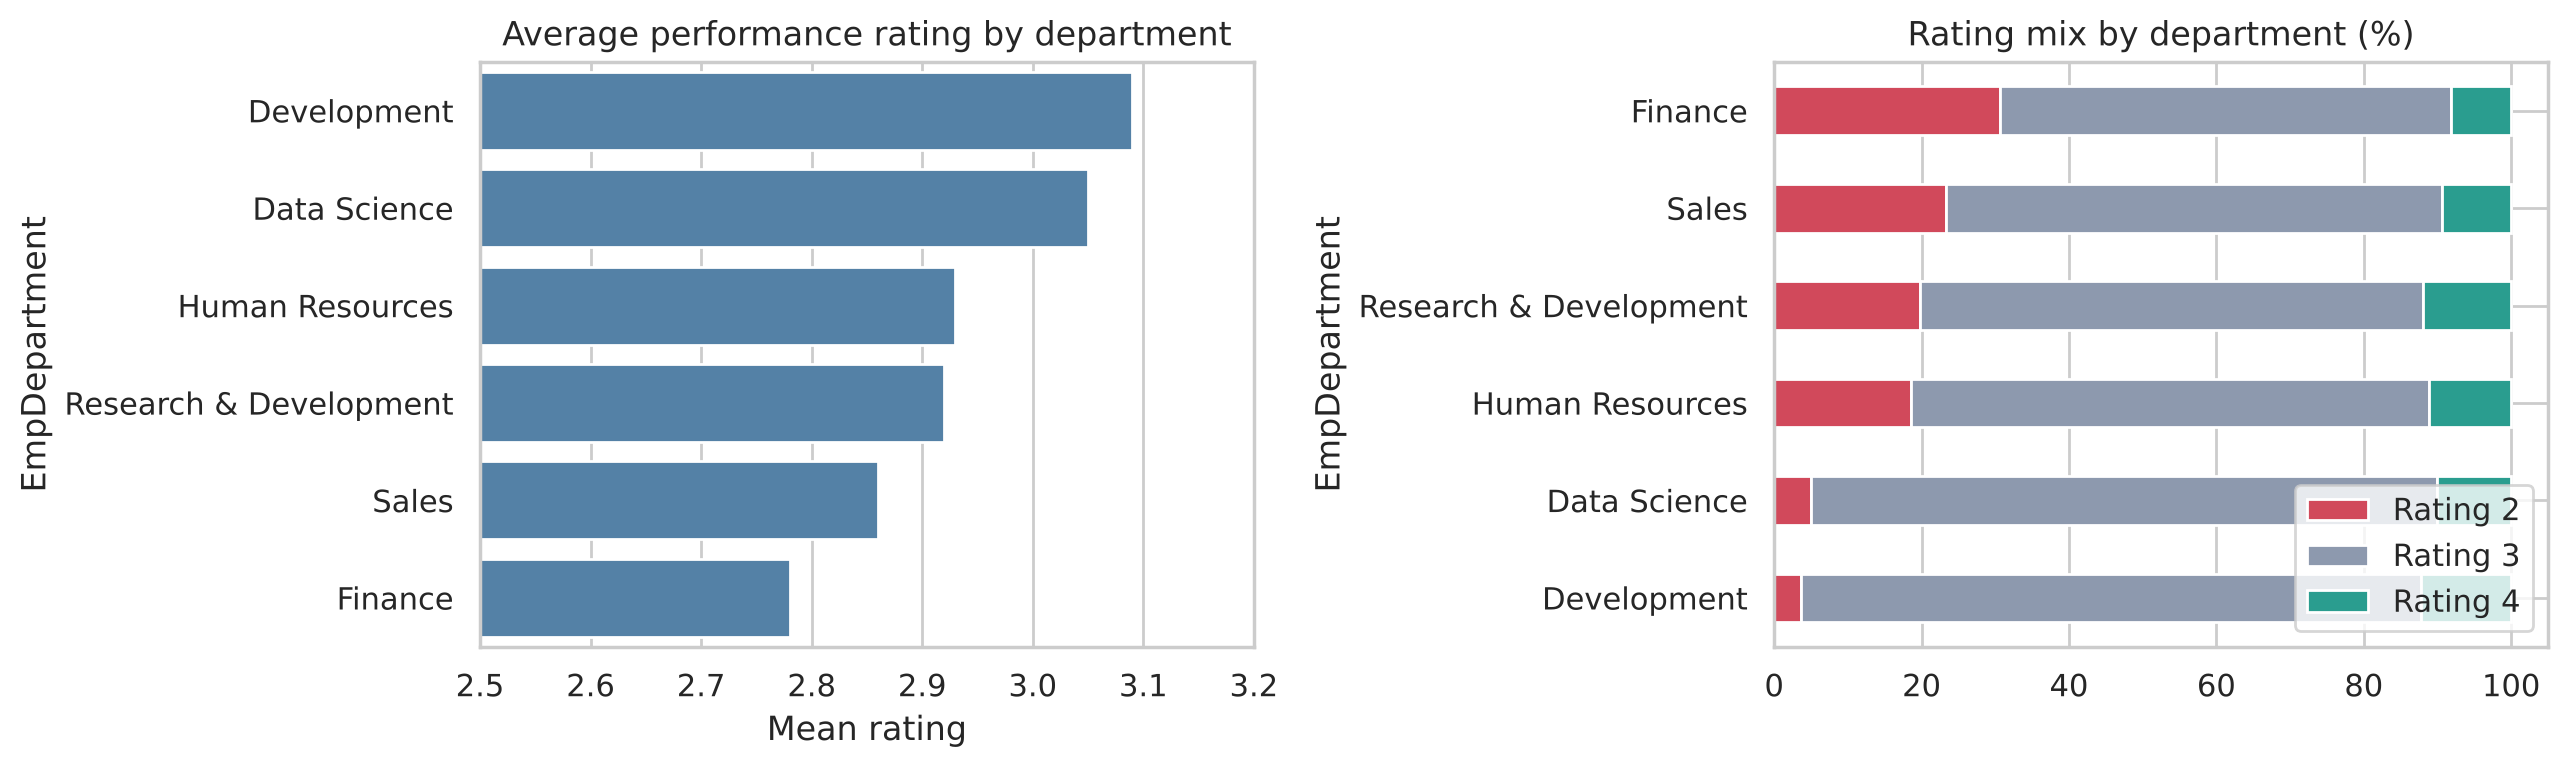

In [5]:
fig, axes = plt.subplots(1,2, figsize=(13,4))
order = dept.index
sns.barplot(x=dept['mean_rating'], y=order, ax=axes[0], color='steelblue')
axes[0].set_xlim(2.5,3.2); axes[0].set_title('Average performance rating by department'); axes[0].set_xlabel('Mean rating')
dept[['pct_rating_2','pct_rating_3','pct_rating_4']].plot(kind='barh', stacked=True, ax=axes[1],
    color=['#d1495b','#8d99ae','#2a9d8f'])
axes[1].set_title('Rating mix by department (%)'); axes[1].legend(['Rating 2','Rating 3','Rating 4'], loc='lower right')
plt.tight_layout(); plt.show()

In [6]:
# Is the difference between departments real, or could it be chance?
groups = [g['PerformanceRating'].values for _, g in df.groupby('EmpDepartment')]
h, p_kw = stats.kruskal(*groups)
chi2, p_chi, dof, _ = stats.chi2_contingency(pd.crosstab(df['EmpDepartment'], df['PerformanceRating']))
print(f'Kruskal-Wallis test (rating differs by department): H = {h:.1f}, p = {p_kw:.2g}')
print(f'Chi-square test (rating mix differs by department): chi2 = {chi2:.1f}, p = {p_chi:.2g}')

Kruskal-Wallis test (rating differs by department): H = 44.9, p = 1.5e-08
Chi-square test (rating mix differs by department): chi2 = 70.3, p = 3.8e-11


In [7]:
role = df.groupby(['EmpDepartment','EmpJobRole']).agg(employees=('PerformanceRating','size'),
        mean_rating=('PerformanceRating','mean'), pct_rating_2=('PerformanceRating', lambda s: 100*(s==2).mean())).round(2)
role.sort_values('mean_rating', ascending=False)

employees  mean_rating  pct_rating_2
EmpDepartment          EmpJobRole                                                     
Research & Development Manager                            8         3.25          0.00
Development            Business Analyst                  16         3.19          0.00
                       Developer                        236         3.11          2.54
                       Technical Lead                    38         3.08          2.63
Data Science           Data Scientist                    20         3.05          5.00
Development            Senior Developer                  52         3.00         11.54
                       Delivery Manager                  12         3.00          0.00
Human Resources        Manager                            9         3.00         11.11
Development            Technical Architect                7         3.00          0.00
Research & Development Manufacturing Director            33         2.97          9.09
                       Research Scientist                77         2.96         22.08
                       Manager R&D                       94         2.94         18.09
Human Resources        Human Resources                   45         2.91         20.00
Research & Development Research Director                 19         2.89         26.32
Sales                  Manager                           34         2.88         32.35
                       Sales Representative              69         2.87         17.39
Research & Development Laboratory Technician             64         2.86         21.88
Sales                  Sales Executive                  270         2.86         23.70
Research & Development Healthcare Representative         33         2.85         24.24
                       Senior Manager R&D                15         2.80         26.67
Finance                Finance Manager                   49         2.78         30.61

**Reading:** the differences between departments are statistically significant (p well below 0.05). Development and Data Science perform best (very few rating-2 employees). Finance, Sales and Research & Development lag, with Finance weakest: nearly one in three Finance employees has a rating of 2.

Department is a useful *signal*, but whether it matters on its own or simply reflects other factors (such as working conditions) is tested in the modelling stage. Note that Development has below-average environment satisfaction yet the best ratings, so department differences cannot be explained by environment satisfaction alone.

## 3. Which factors relate to performance?

In [8]:
# Numeric / ordinal variables: Spearman rank correlation with the rating (robust to non-normal data)
num_cols = [c for c in mr.columns if mr[c].nunique() > 2 and c != 'PerformanceRating']
rows = []
for c in num_cols:
    rho, p = stats.spearmanr(mr[c], mr['PerformanceRating'])
    rows.append((c, rho, p))
corr_tbl = pd.DataFrame(rows, columns=['feature','spearman_rho','p_value']).sort_values('spearman_rho', key=abs, ascending=False)
corr_tbl['significant (p<0.05)'] = corr_tbl['p_value'] < 0.05
corr_tbl.round(4).head(12)

,feature,spearman_rho,p_value,significant (p<0.05)
4,EmpEnvironmentSatisfaction,0.3966,0.0000,True
10,EmpLastSalaryHikePercent,0.2737,0.0000,True
17,YearsSinceLastPromotion,-0.2697,0.0000,True
19,PromotionDelayRatio,-0.2687,0.0000,True
16,ExperienceYearsInCurrentRole,-0.1661,0.0000,True
20,RoleStagnationRatio,-0.1518,0.0000,True
18,YearsWithCurrManager,-0.1350,0.0000,True
15,ExperienceYearsAtThisCompany,-0.1325,0.0000,True
14,EmpWorkLifeBalance,0.1137,0.0001,True
21,AvgYearsPerCompany,-0.1095,0.0001,True


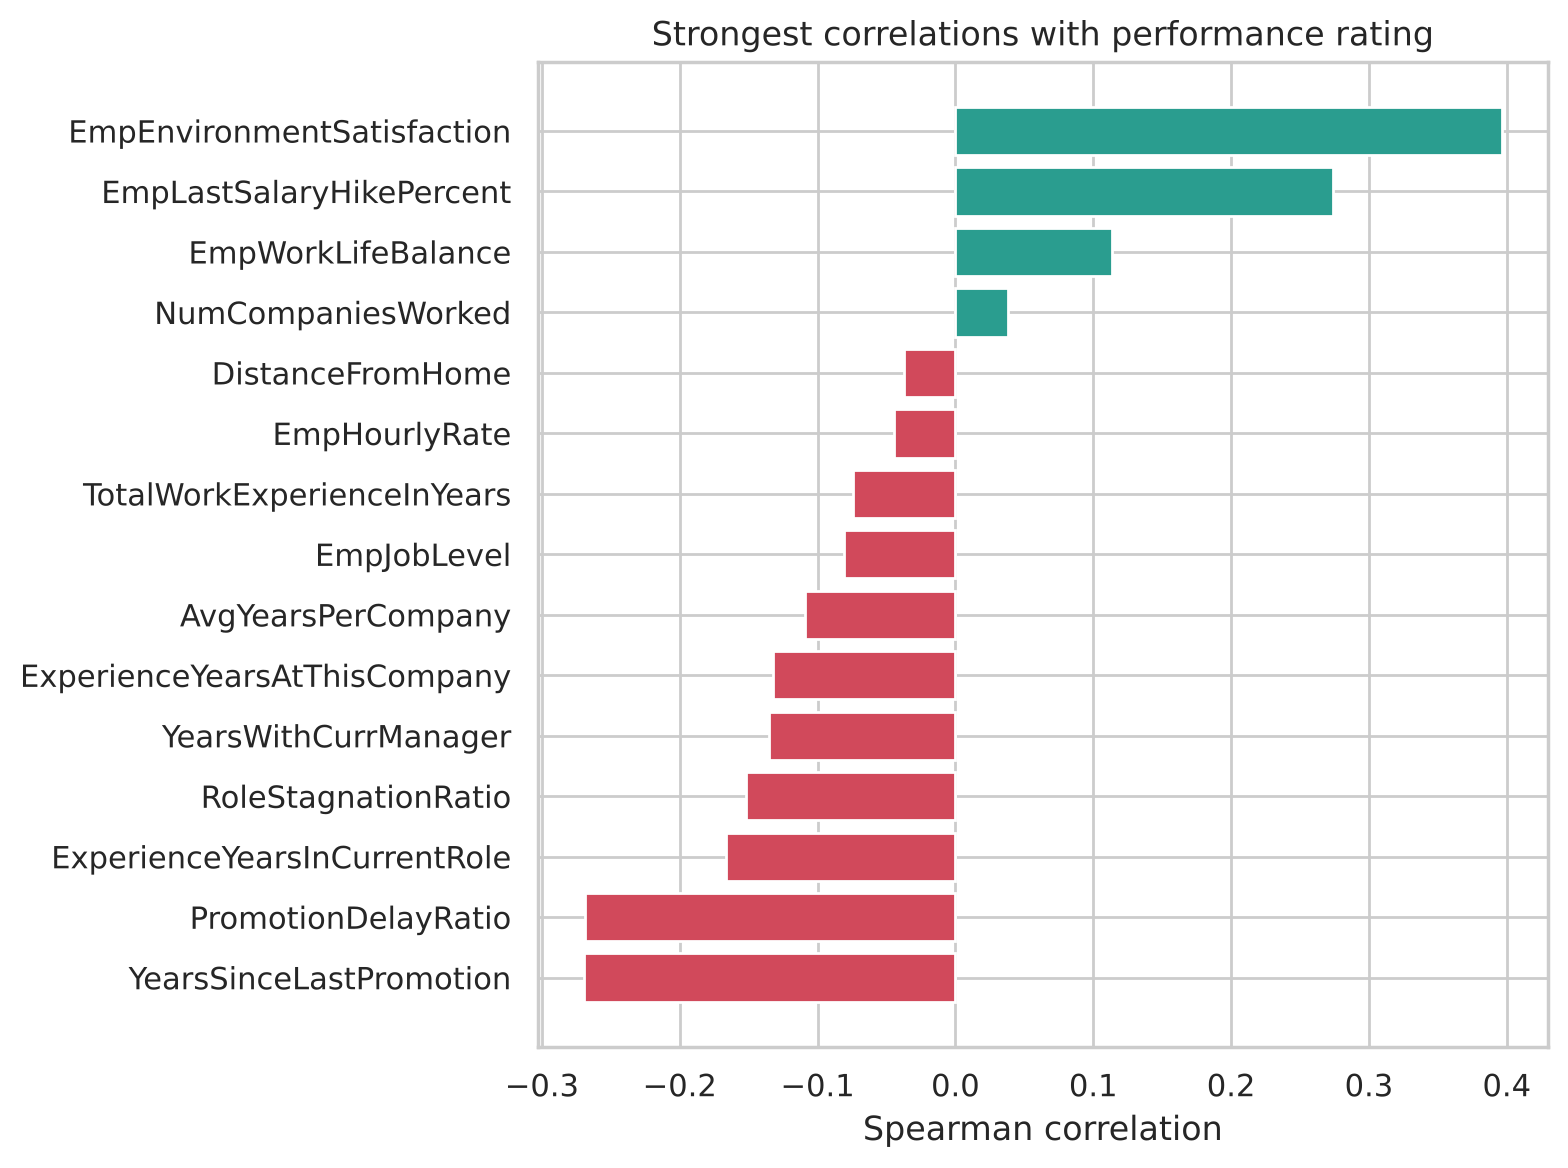

In [9]:
fig, ax = plt.subplots(figsize=(8,6))
top = corr_tbl.head(15).sort_values('spearman_rho')
ax.barh(top['feature'], top['spearman_rho'], color=np.where(top['spearman_rho']>0,'#2a9d8f','#d1495b'))
ax.set_title('Strongest correlations with performance rating'); ax.set_xlabel('Spearman correlation')
plt.tight_layout(); plt.show()

In [10]:
# Categorical variables: does the rating mix differ between categories? (chi-square test)
cat_cols = ['Gender','EducationBackground','MaritalStatus','EmpDepartment','EmpJobRole','BusinessTravelFrequency','OverTime','Attrition']
res = []
for c in cat_cols:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[c], df['PerformanceRating']))
    n = len(df); k = min(pd.crosstab(df[c], df['PerformanceRating']).shape)-1
    cramers_v = np.sqrt(chi2/(n*k))
    res.append((c, p, cramers_v))
pd.DataFrame(res, columns=['categorical_feature','p_value','association_strength (Cramer V)']).sort_values('p_value').round(4)

,categorical_feature,p_value,association_strength (Cramer V)
3,EmpDepartment,0.0000,0.1712
4,EmpJobRole,0.0000,0.2018
6,OverTime,0.0035,0.0970
2,MaritalStatus,0.1894,0.0506
7,Attrition,0.2771,0.0463
5,BusinessTravelFrequency,0.3549,0.0428
1,EducationBackground,0.4216,0.0652
0,Gender,0.9218,0.0117


**Reading**
- Strongest relationships (Spearman): **environment satisfaction** (+0.40), **last salary hike %** (+0.27) and **years since last promotion** (-0.27), followed by tenure variables (years in current role, with current manager, at company: all negative).
- Work-life balance has a smaller positive relationship (+0.11).
- **Gender, marital status, education background, business travel and attrition show no statistically significant relationship** with performance (p > 0.05). This is good news from a fairness point of view: performance is not linked to who the person is.
- Overtime has a statistically significant but weak association, and in the opposite direction to what one might expect (overtime workers have slightly *fewer* rating-2 employees: 11% vs 18%).
- **Caution:** correlation is not causation. Salary hikes and promotions are often *given for* good performance, so part of these relationships may run from rating to hike or promotion rather than the other way round.

## 4. A closer look at the top relationships

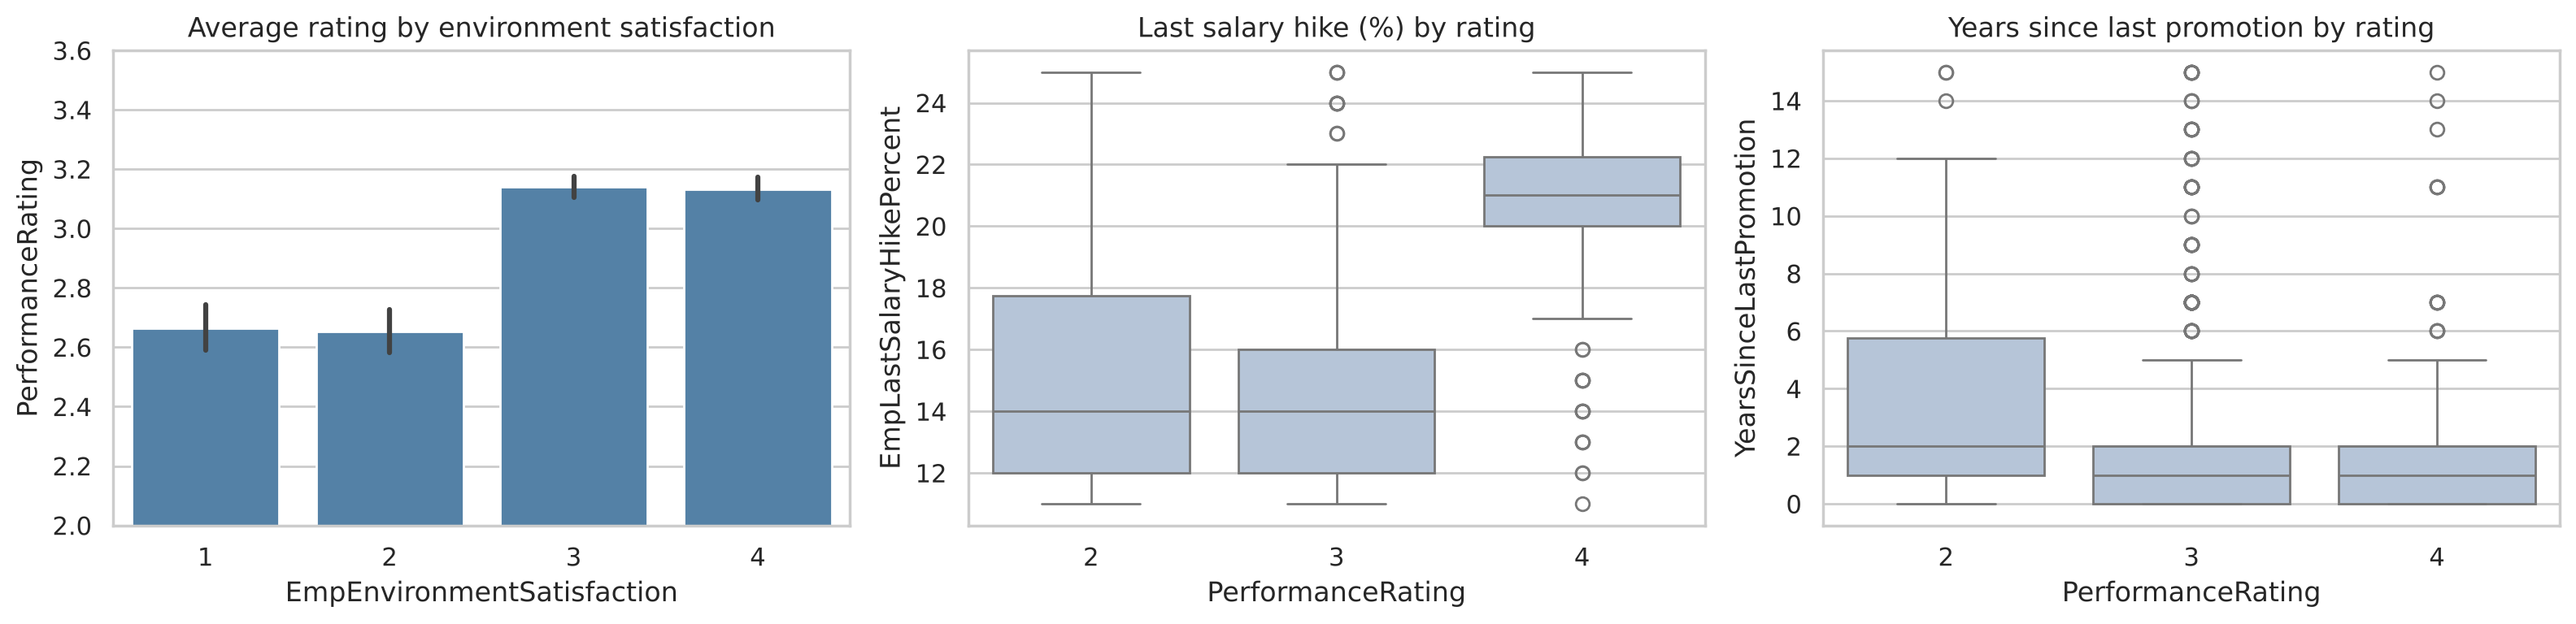

In [11]:
fig, axes = plt.subplots(1,3, figsize=(16,4))
sns.barplot(data=df, x='EmpEnvironmentSatisfaction', y='PerformanceRating', ax=axes[0], color='steelblue', errorbar=('ci',95))
axes[0].set_title('Average rating by environment satisfaction'); axes[0].set_ylim(2,3.6)
sns.boxplot(data=df, x='PerformanceRating', y='EmpLastSalaryHikePercent', ax=axes[1], color='lightsteelblue')
axes[1].set_title('Last salary hike (%) by rating')
sns.boxplot(data=df, x='PerformanceRating', y='YearsSinceLastPromotion', ax=axes[2], color='lightsteelblue')
axes[2].set_title('Years since last promotion by rating')
plt.tight_layout(); plt.show()

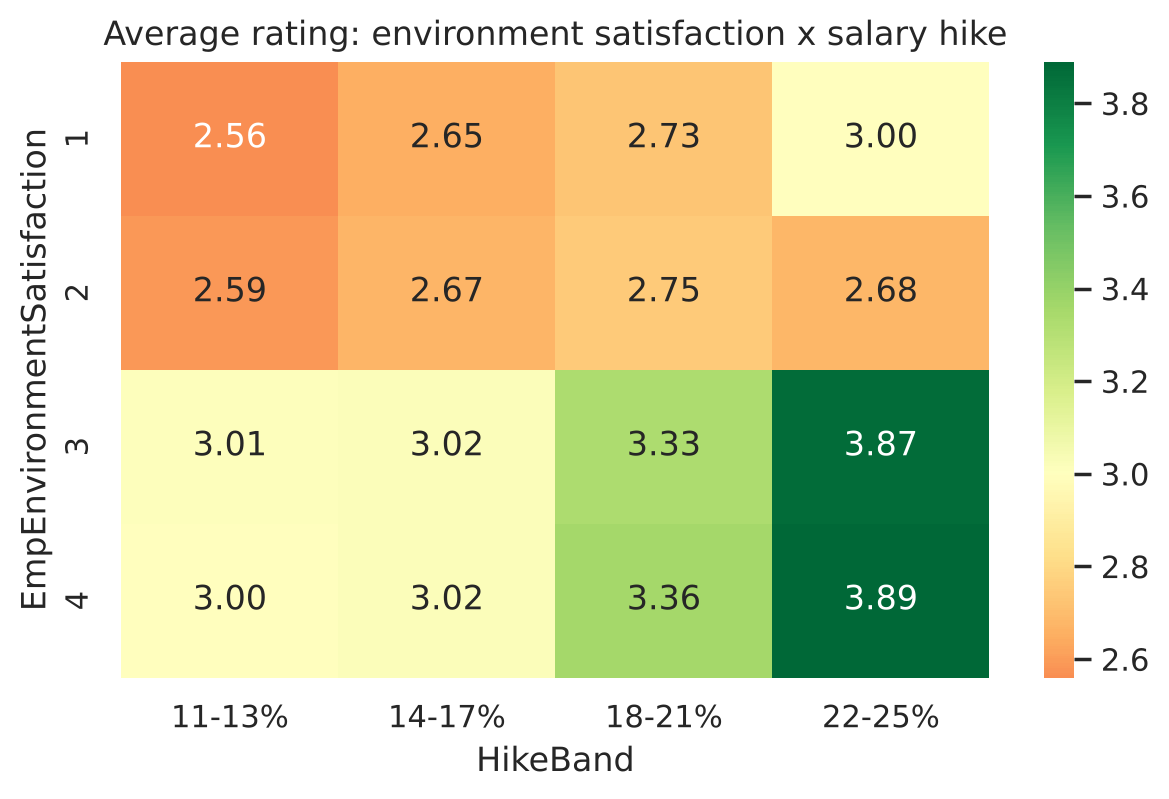

In [12]:
# Environment satisfaction x salary hike band together (interaction)
df['HikeBand'] = pd.cut(df['EmpLastSalaryHikePercent'], [10,13,17,21,25], labels=['11-13%','14-17%','18-21%','22-25%'])
pv = df.pivot_table(index='EmpEnvironmentSatisfaction', columns='HikeBand', values='PerformanceRating', aggfunc='mean').round(2)
cnt = df.pivot_table(index='EmpEnvironmentSatisfaction', columns='HikeBand', values='PerformanceRating', aggfunc='size')
fig, ax = plt.subplots(figsize=(7,4))
sns.heatmap(pv, annot=True, cmap='RdYlGn', center=3, ax=ax, fmt='.2f')
ax.set_title('Average rating: environment satisfaction x salary hike')
plt.show()

**Reading:** the average rating is highest where environment satisfaction *and* the salary hike are both high, and lowest where satisfaction is low and the hike is small. Long gaps since the last promotion go with lower ratings. The next cells show that the three factors play *different* roles.

In [13]:
# The three factors play different roles: look at the share of each rating inside each group
def mix(by):
    t = pd.crosstab(by, df['PerformanceRating'], normalize='index').mul(100).round(1)
    t.columns = ['% rating 2','% rating 3','% rating 4']; t['employees'] = by.value_counts().sort_index(); return t

print('Environment satisfaction'); display(mix(df['EmpEnvironmentSatisfaction']))
print('Last salary hike band');    display(mix(df['HikeBand']))
print('Years since last promotion'); display(mix(pd.cut(df['YearsSinceLastPromotion'], [-1,0,2,5,15], labels=['0 (this year)','1-2','3-5','6+'])))

Environment satisfaction


,% rating 2,% rating 3,% rating 4,employees
EmpEnvironmentSatisfaction,,,,
1,39.1,55.2,5.7,230
2,40.5,53.7,5.8,242
3,0.8,84.5,14.7,367
4,0.8,85.0,14.1,361


Last salary hike band


,% rating 2,% rating 3,% rating 4,employees
HikeBand,,,,
11-13%,17.3,81.5,1.2,492
14-17%,15.4,81.2,3.3,389
18-21%,15.0,60.9,24.1,220
22-25%,16.2,23.2,60.6,99


Years since last promotion


,% rating 2,% rating 3,% rating 4,employees
YearsSinceLastPromotion,,,,
0 (this year),0.6,86.4,13.0,469
1-2,24.3,65.6,10.1,424
3-5,29.3,62.4,8.3,133
6+,28.2,62.1,9.8,174


**What this shows**
- **Environment satisfaction acts like a floor.** Of the 194 employees rated 2, **188 (97%)** report environment satisfaction of 1 or 2. Among employees with satisfaction 3 or 4, only about 1% are rated 2.
- **Salary hike separates the top performers.** Hardly any employee with a hike of 17% or less is rated 4, while 24% of those with hikes of 18-21% and 61% of those with hikes above 21% are rated 4. Hike size is unrelated to the share of rating-2 employees.
- **Recent promotion protects against low ratings.** Only 1% of employees promoted this year are rated 2, versus roughly 24-29% of everyone else.

## 5. Multicollinearity among the features

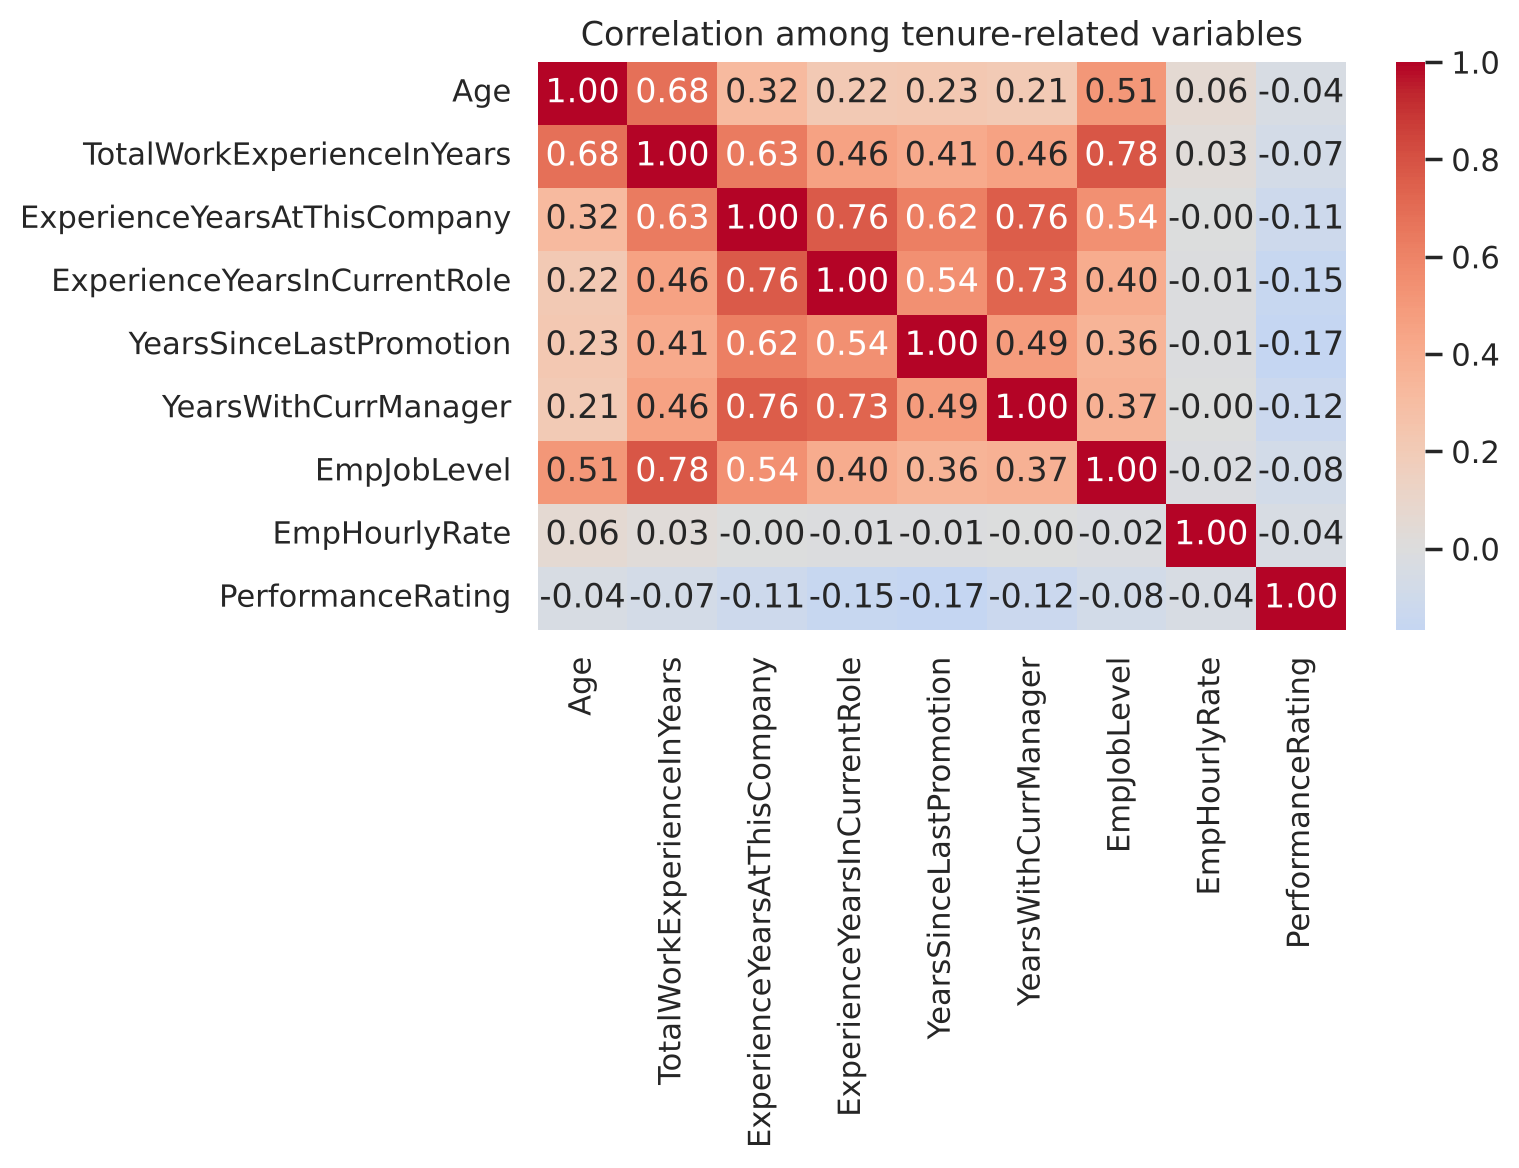

Highly correlated pairs (|r| > 0.6):
TotalWorkExperienceInYears    EmpJobLevel                     0.78
ExperienceYearsAtThisCompany  ExperienceYearsInCurrentRole    0.76
                              YearsWithCurrManager            0.76
ExperienceYearsInCurrentRole  YearsWithCurrManager            0.73
Age                           TotalWorkExperienceInYears      0.68
TotalWorkExperienceInYears    ExperienceYearsAtThisCompany    0.63
ExperienceYearsAtThisCompany  YearsSinceLastPromotion         0.62
dtype: float64


In [14]:
tenure = ['Age','TotalWorkExperienceInYears','ExperienceYearsAtThisCompany','ExperienceYearsInCurrentRole',
          'YearsSinceLastPromotion','YearsWithCurrManager','EmpJobLevel','EmpHourlyRate']
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(df[tenure+['PerformanceRating']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation among tenure-related variables'); plt.tight_layout(); plt.show()

c = df[tenure].corr().abs().where(np.triu(np.ones((len(tenure),len(tenure))),1).astype(bool)).stack()
print('Highly correlated pairs (|r| > 0.6):'); print(c[c>0.6].sort_values(ascending=False).round(2))

Tenure variables (age, total experience, years at the company, years in role, years with manager) are strongly correlated with each other. Linear models struggle with this, which is one reason to prefer **tree-based ensemble models** that handle correlated features well. For *interpretation*, we avoid reading the importance of any single tenure variable in isolation; instead we use permutation importance on the whole fitted model.

## 6. Is dimensionality reduction (PCA) useful here?

Components needed for 80% variance: 31 of 59
Components needed for 90% variance: 37 of 59


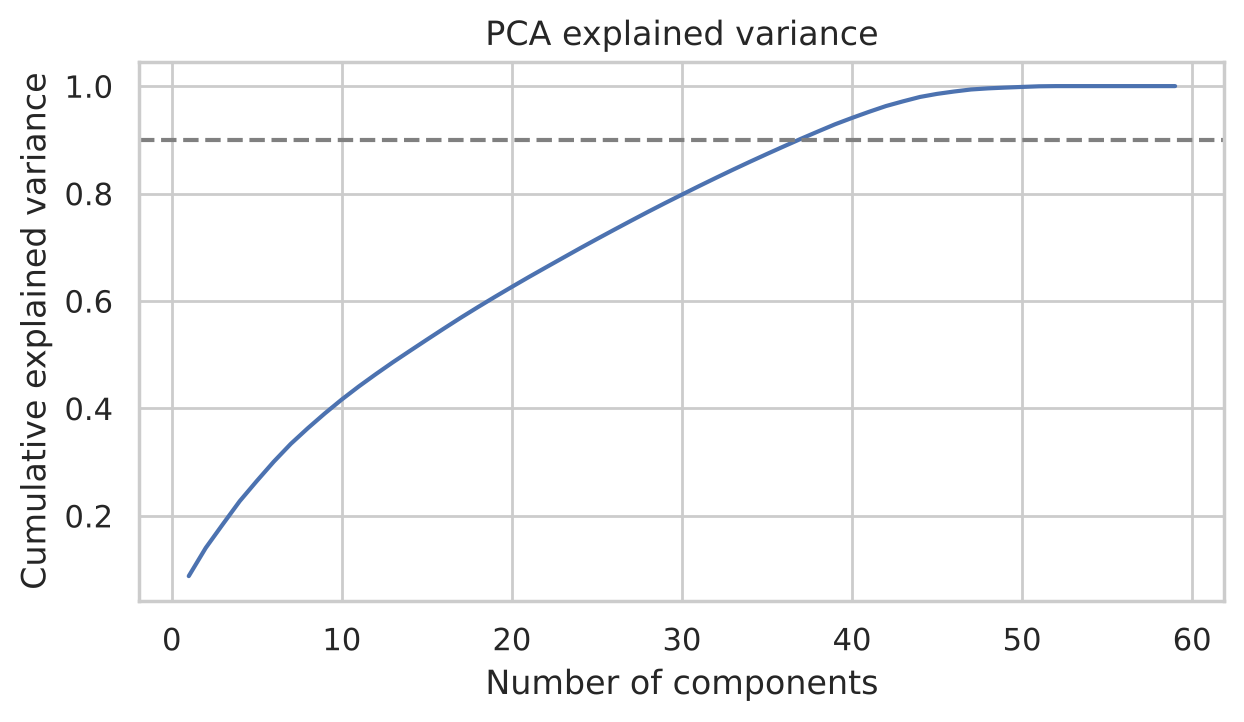

In [15]:
X_num = StandardScaler().fit_transform(mr.drop(columns=['PerformanceRating']))
pca = PCA().fit(X_num)
cum = np.cumsum(pca.explained_variance_ratio_)
print('Components needed for 80% variance:', int(np.argmax(cum>=.80))+1, 'of', X_num.shape[1])
print('Components needed for 90% variance:', int(np.argmax(cum>=.90))+1, 'of', X_num.shape[1])
fig, ax = plt.subplots(figsize=(7,3.5)); ax.plot(range(1,len(cum)+1), cum); ax.axhline(.9, ls='--', c='grey')
ax.set_xlabel('Number of components'); ax.set_ylabel('Cumulative explained variance'); ax.set_title('PCA explained variance'); plt.show()

PCA needs many components to retain most of the variance (the variation is spread over many features, mostly because of the one-hot encoded categories). More importantly, **the business needs to know *which real-world factors* drive performance**, and PCA components are blends of many variables that cannot be explained to management. **We therefore do not use PCA** and keep the original, interpretable features.

## 7. Profile of lower-performing employees (rating 2)

In [16]:
df['Group'] = np.where(df['PerformanceRating']==2, 'Rating 2 (lower)', 'Rating 3-4')
key = ['EmpEnvironmentSatisfaction','EmpLastSalaryHikePercent','YearsSinceLastPromotion','EmpWorkLifeBalance',
       'ExperienceYearsInCurrentRole','YearsWithCurrManager','ExperienceYearsAtThisCompany','Age','EmpJobLevel']
prof = df.groupby('Group')[key].mean().T.round(2)
prof['difference'] = (prof['Rating 2 (lower)'] - prof['Rating 3-4']).round(2)
prof

Group,Rating 2 (lower),Rating 3-4,difference
EmpEnvironmentSatisfaction,1.58,2.93,-1.35
EmpLastSalaryHikePercent,15.07,15.25,-0.18
YearsSinceLastPromotion,3.70,1.90,1.80
EmpWorkLifeBalance,2.63,2.77,-0.14
ExperienceYearsInCurrentRole,5.79,4.00,1.79
YearsWithCurrManager,5.35,3.86,1.49
ExperienceYearsAtThisCompany,9.10,6.69,2.41
Age,37.80,36.75,1.05
EmpJobLevel,2.30,2.02,0.28


In [17]:
low = df[df.PerformanceRating==2]
print('Lower performers: share with environment satisfaction 1-2 :', f"{100*(low.EmpEnvironmentSatisfaction<=2).mean():.0f}%", 
      '| everyone else:', f"{100*(df[df.PerformanceRating>2].EmpEnvironmentSatisfaction<=2).mean():.0f}%")
print('Outstanding (4) employees: share with last salary hike >= 18% :', f"{100*(df[df.PerformanceRating==4].EmpLastSalaryHikePercent>=18).mean():.0f}%",
      '| everyone else:', f"{100*(df[df.PerformanceRating<4].EmpLastSalaryHikePercent>=18).mean():.0f}%")
print('Lower performers: share 3+ yrs since promotion             :', f"{100*(low.YearsSinceLastPromotion>=3).mean():.0f}%",
      '| everyone else:', f"{100*(df[df.PerformanceRating>2].YearsSinceLastPromotion>=3).mean():.0f}%")

Lower performers: share with environment satisfaction 1-2 : 97% | everyone else: 28%
Outstanding (4) employees: share with last salary hike >= 18% : 86% | everyone else: 19%
Lower performers: share 3+ yrs since promotion             : 45% | everyone else: 22%


## Summary of exploratory findings

1. **Departments differ significantly.** Development and Data Science are strongest; Finance, Sales and Research & Development are weakest.
2. **Three factors stand out:** environment satisfaction, last salary hike percentage, and years since last promotion (plus related tenure variables).
3. **Personal characteristics (gender, marital status, education) do not matter.**
4. **Lower performers have a very recognisable profile:** 97% report low environment satisfaction (1-2) and most have not been promoted recently. Salary hike is what distinguishes *outstanding* employees.
5. Hikes and promotions may partly be *consequences* of performance, so causal claims need care.
6. Features are correlated (especially tenure variables) and classes are imbalanced, so we use tree-based ensembles, stratified validation and macro-F1 in the modelling stage. PCA is deliberately not used, to keep results explainable.